# Lab 4 Task 3: PN Channel Estimation

Generate one degree-10 PN period, validate acquisition with a synthetic record, transmit it once with GNU Radio, and estimate the scalar link coefficient from a N310 capture.


In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab4_tools.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 4 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB4_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)
print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures


## Waveform and file calculations


<span style="color:#165696"><b>Report.</b> Calculate the PN length, transmit duration, waveform byte count, receive
sample count, and receive byte count. </span>

In [2]:
pn_degree = 10
sample_rate_sps = 1_250_000
acquisition_lead_seconds = 2.0
edge_guard_samples = 4096
capture_seconds = 10.0

# Derive every count from the parameters above
pn_length = 2**pn_degree - 1
acquisition_lead_samples = int(acquisition_lead_seconds * sample_rate_sps)
waveform_samples = acquisition_lead_samples + pn_length + 2 * edge_guard_samples
waveform_bytes = waveform_samples * 8  # complex64 = 8 bytes/sample
waveform_duration_seconds = waveform_samples / sample_rate_sps
capture_samples = int(capture_seconds * sample_rate_sps)
capture_bytes = capture_samples * 8  # complex64 = 8 bytes/sample

print("PN length:", pn_length)
print("waveform samples and bytes:", waveform_samples, waveform_bytes)
print("waveform duration (s):", waveform_duration_seconds)
print("capture samples and bytes:", capture_samples, capture_bytes)


PN length: 1023
waveform samples and bytes: 2509215 20073720
waveform duration (s): 2.007372
capture samples and bytes: 12500000 100000000


In [3]:
assert pn_length == 1023
assert acquisition_lead_samples == 2_500_000
assert waveform_samples == 2_509_215
assert waveform_bytes == 20_073_720
assert np.isclose(waveform_duration_seconds, 2.007372)
assert capture_samples == 12_500_000
assert capture_bytes == 100_000_000
print("Waveform and capture calculations passed.")


Waveform and capture calculations passed.


## Generate and inspect the transmit file


/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/waveforms/task3_degree10_pn_burst_c64.dat 20073720 bytes


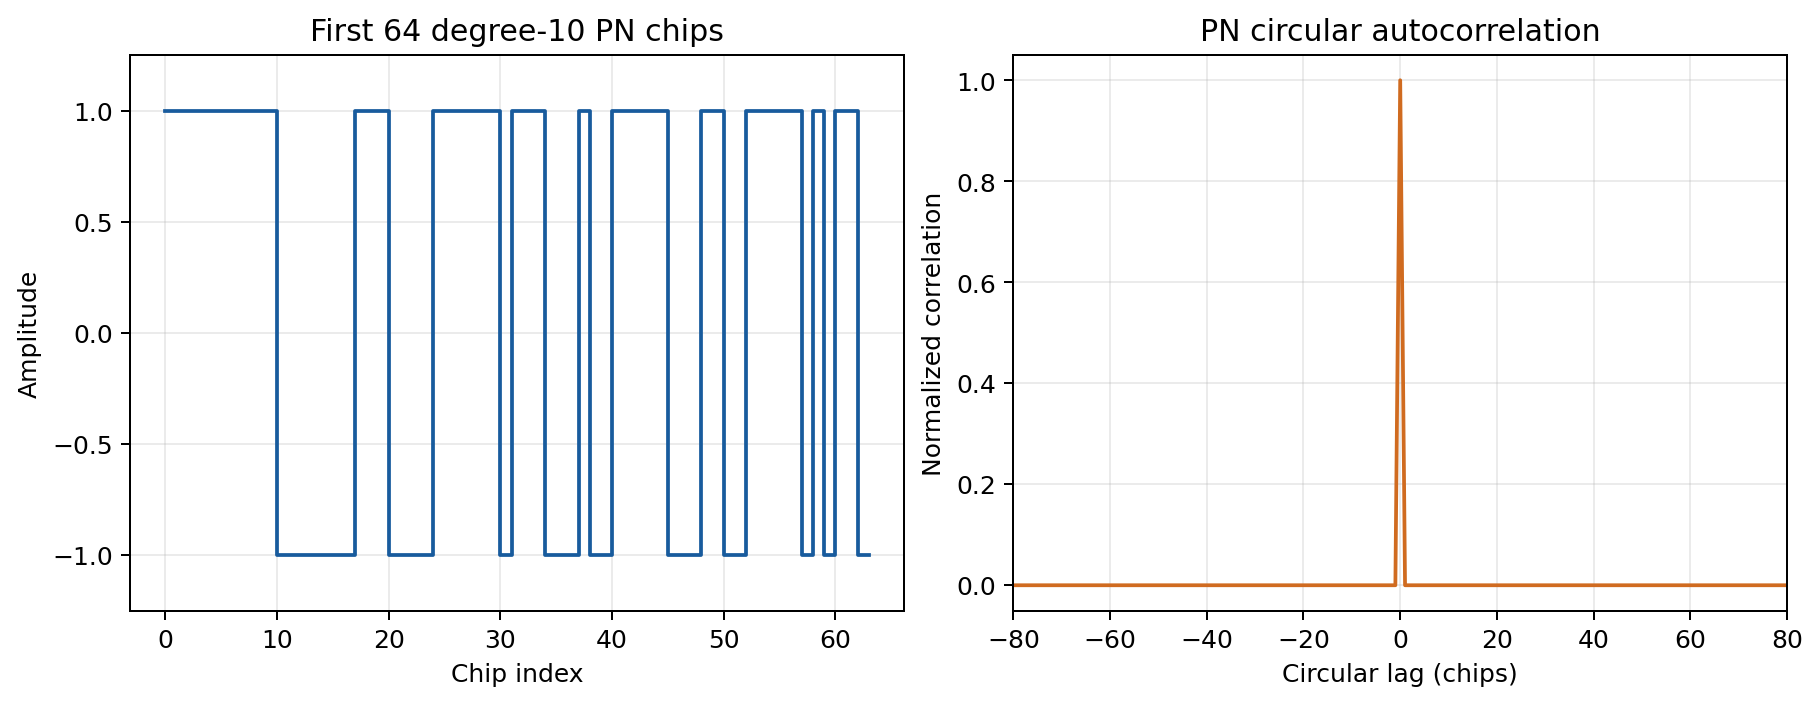

In [4]:
from lab4_tools import generate_pn_waveform, plot_pn_sequence

reference, waveform_path = generate_pn_waveform(
    WAVEFORM_DIR / "task3_degree10_pn_burst_c64.dat"
)
sequence_figure = plot_pn_sequence(FIGURE_DIR)
print(waveform_path, waveform_path.stat().st_size, "bytes")
display(Image(filename=sequence_figure))


## Synthetic receiver check


expected and recovered start: 26096 26096
true and estimated CFO: -245.0 -243.93136865932303
chip error rate: 0.0


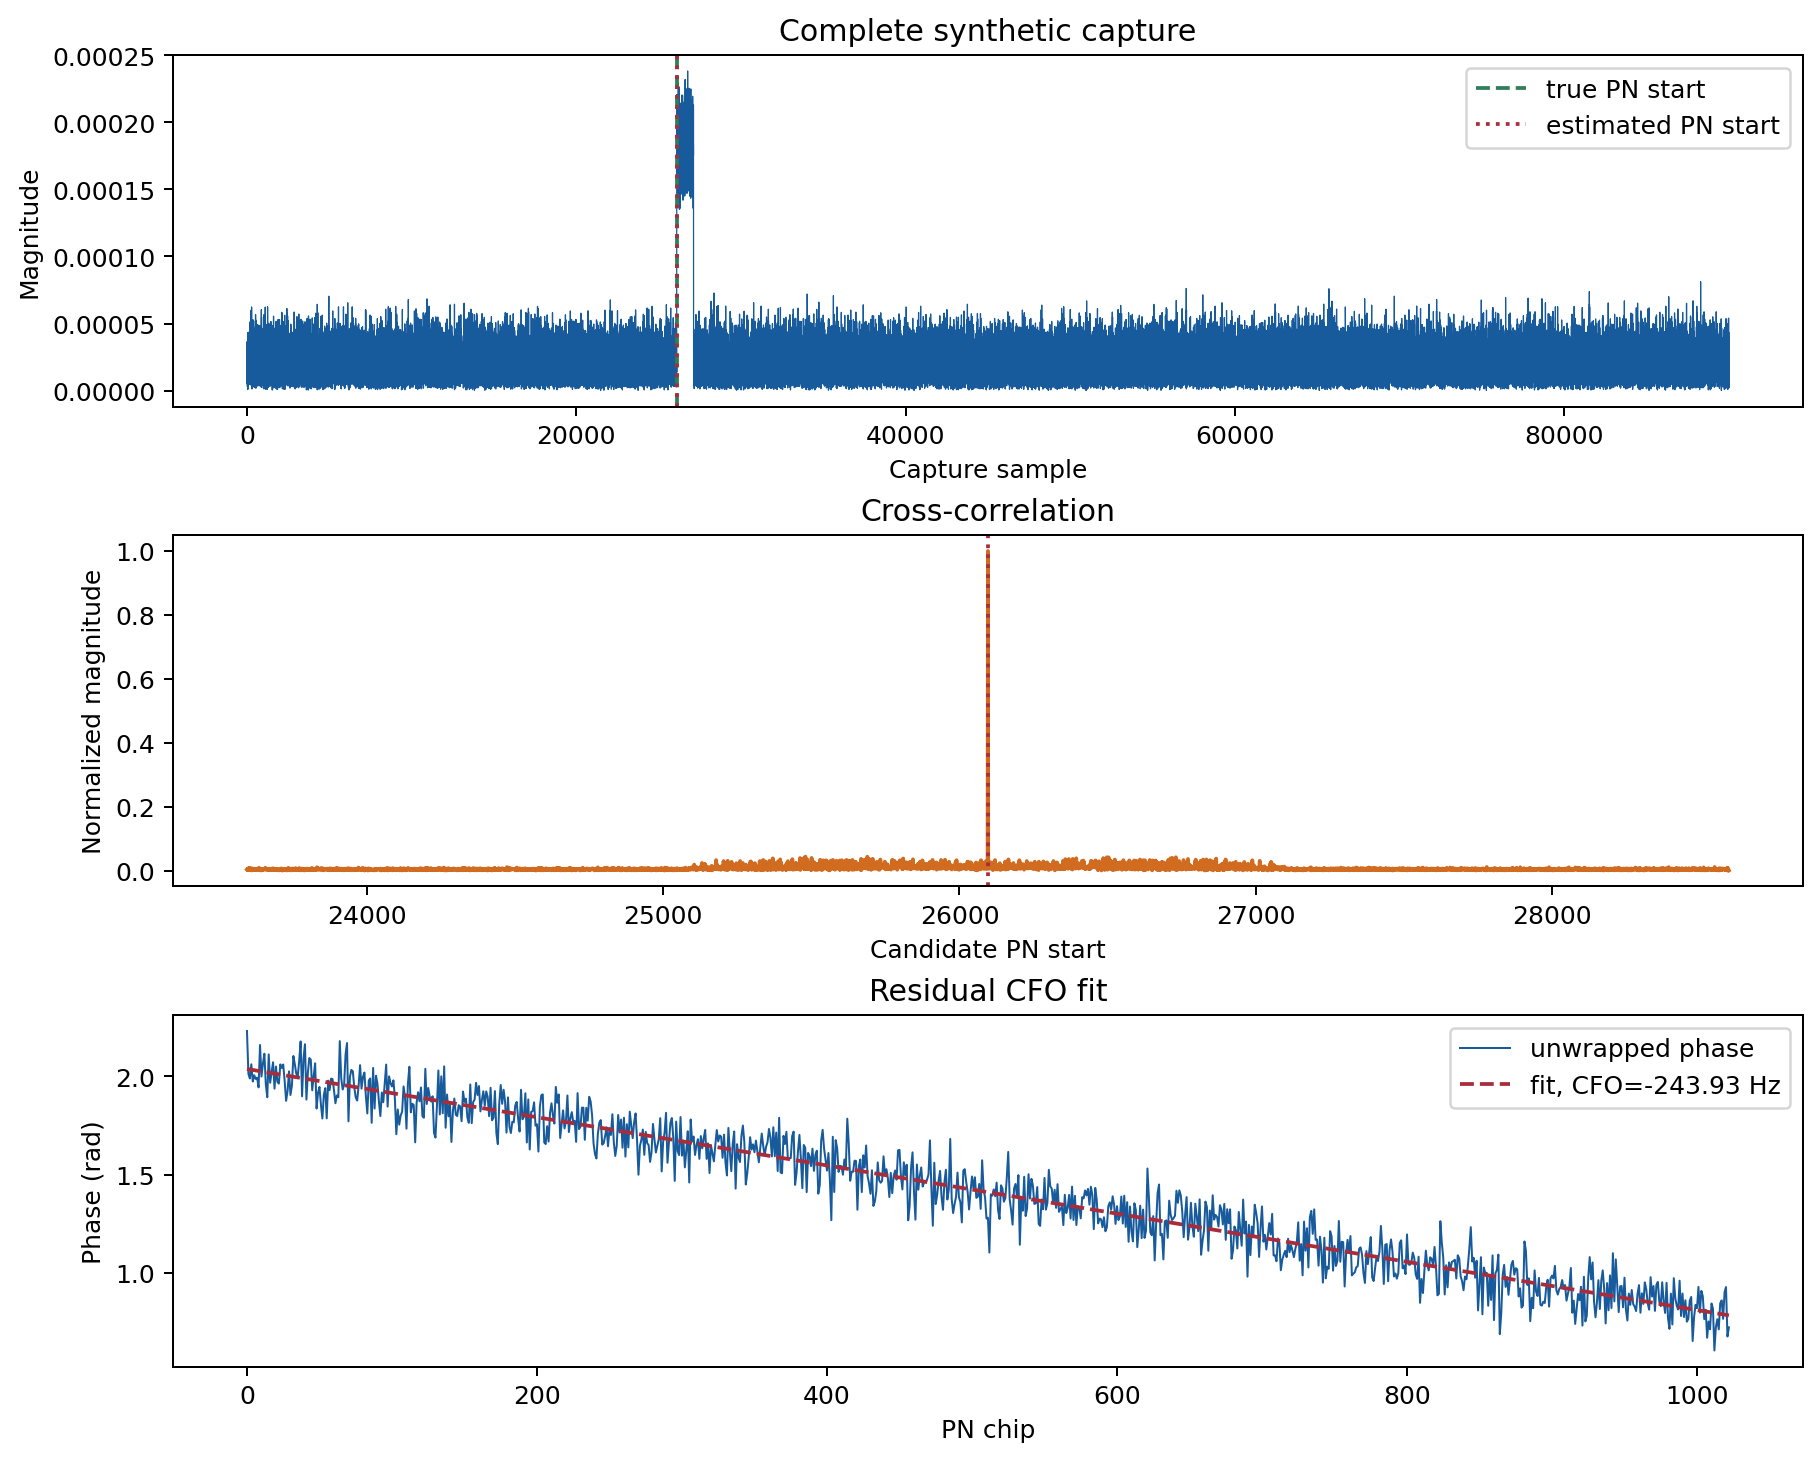

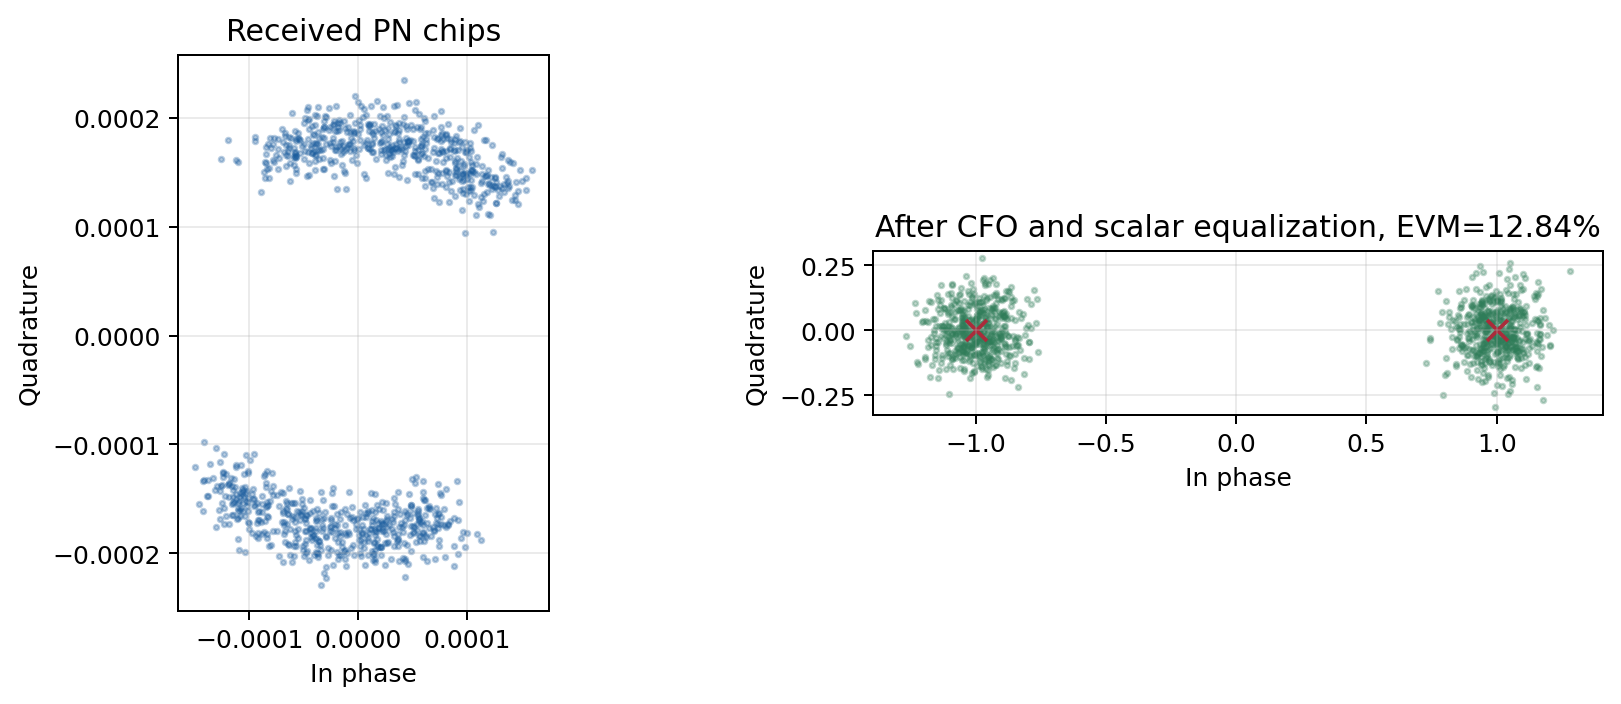

In [5]:
from lab4_tools import make_synthetic_pn_capture, plot_synthetic_pn

delay_samples=22_000
synthetic_capture, synthetic_result, truth = make_synthetic_pn_capture(delay_samples=22_000)

# To do: predict the PN start from the inserted delay and edge guard.
expected_start_sample = edge_guard_samples + delay_samples
assert expected_start_sample == truth["start_sample"]
assert synthetic_result["start_sample"] == expected_start_sample
print("expected and recovered start:", expected_start_sample, synthetic_result["start_sample"])
print("true and estimated CFO:", truth["cfo_hz"], synthetic_result["cfo_hz"])
print("chip error rate:", synthetic_result["chip_error_rate"])

for path in plot_synthetic_pn(synthetic_capture, synthetic_result, truth, FIGURE_DIR):
    display(Image(filename=path))


## GNU Radio run

1. On the RX server, open `flowgraphs/lab4_finite_pn_receiver.grc` and enter the assigned RX device address, subdevice, antenna, gain, output filenames, and squelch threshold.
2. On the TX server, open `flowgraphs/lab4_finite_pn_transmitter.grc` and enter the assigned TX address, subdevice, antenna, gain, and transmit filename.
3. Capture one second of noise with the transmitter stopped.
4. Start the 10-second receiver first. Start the one-shot transmitter immediately afterward.
5. Confirm 12,500,000 raw complex64 samples and 100,000,000 bytes.
6. Keep both raw and squelched files. Use the raw file for correlation and least squares.

The two-second quiet lead-in occurs inside the finite file. The PN period itself is transmitted only once.


<span style="color:#165696"><b>Report.</b> Confirm 12,500,000 raw complex64 samples and 100,000,000 bytes. </span>

Examining the head block on the Rx flowgraph for raw and squelched files reveals the 12.5M raw complex64 samples.

In [34]:
!ls -la $CAPTURE_DIR/task3_gain25_run1_raw_c64.dat
!ls -la $CAPTURE_DIR/task3_gain25_run1_squelched_c64.dat
!ls -la $CAPTURE_DIR/task3_noise_c64.dat

-rw-r--r--  1 marcpham  staff  100000000 Oct 13 09:02 /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures/task3_gain25_run1_raw_c64.dat
-rw-r--r--  1 marcpham  staff  100000000 Oct 13 09:01 /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures/task3_gain25_run1_squelched_c64.dat
-rw-r--r--  1 marcpham  staff  10000000 Oct 13 09:01 /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures/task3_noise_c64.dat


<span style="color:#165696"><b>Report.</b> Include screenshots of both GNU Radio canvases and record all radio metadata. </span>

### Rx Flowgraph for Noise Capture

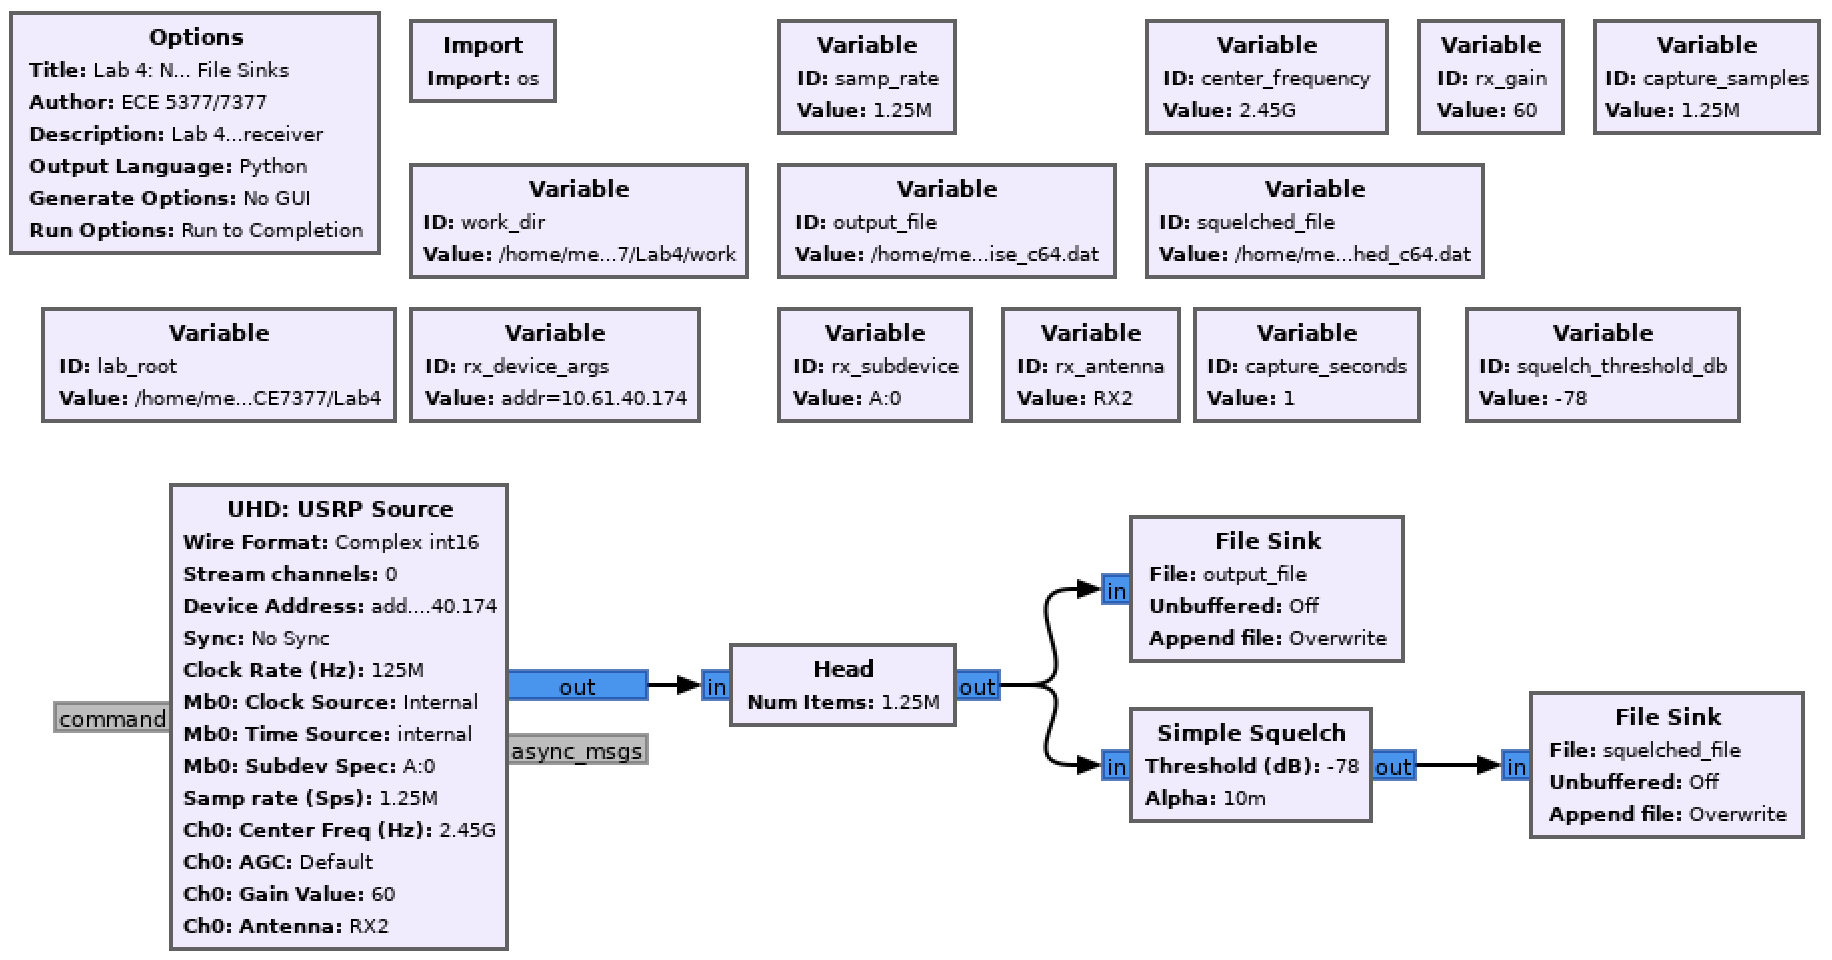

### Tx/Rx Flowgraphs for Raw and Squelched Files

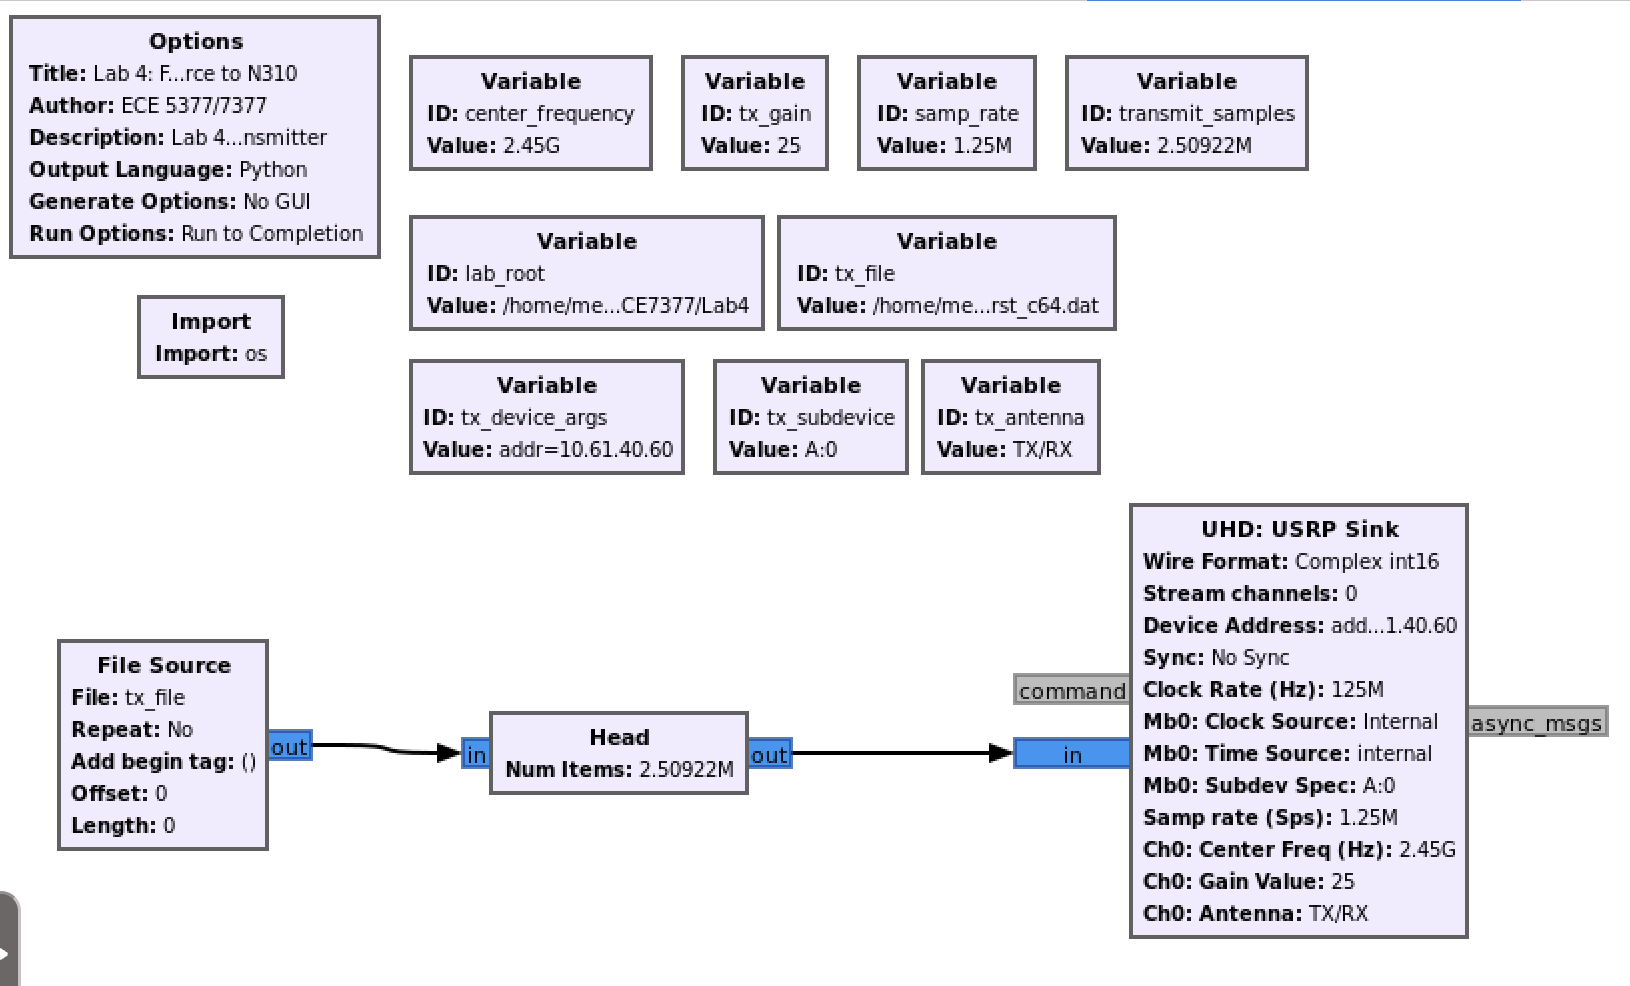

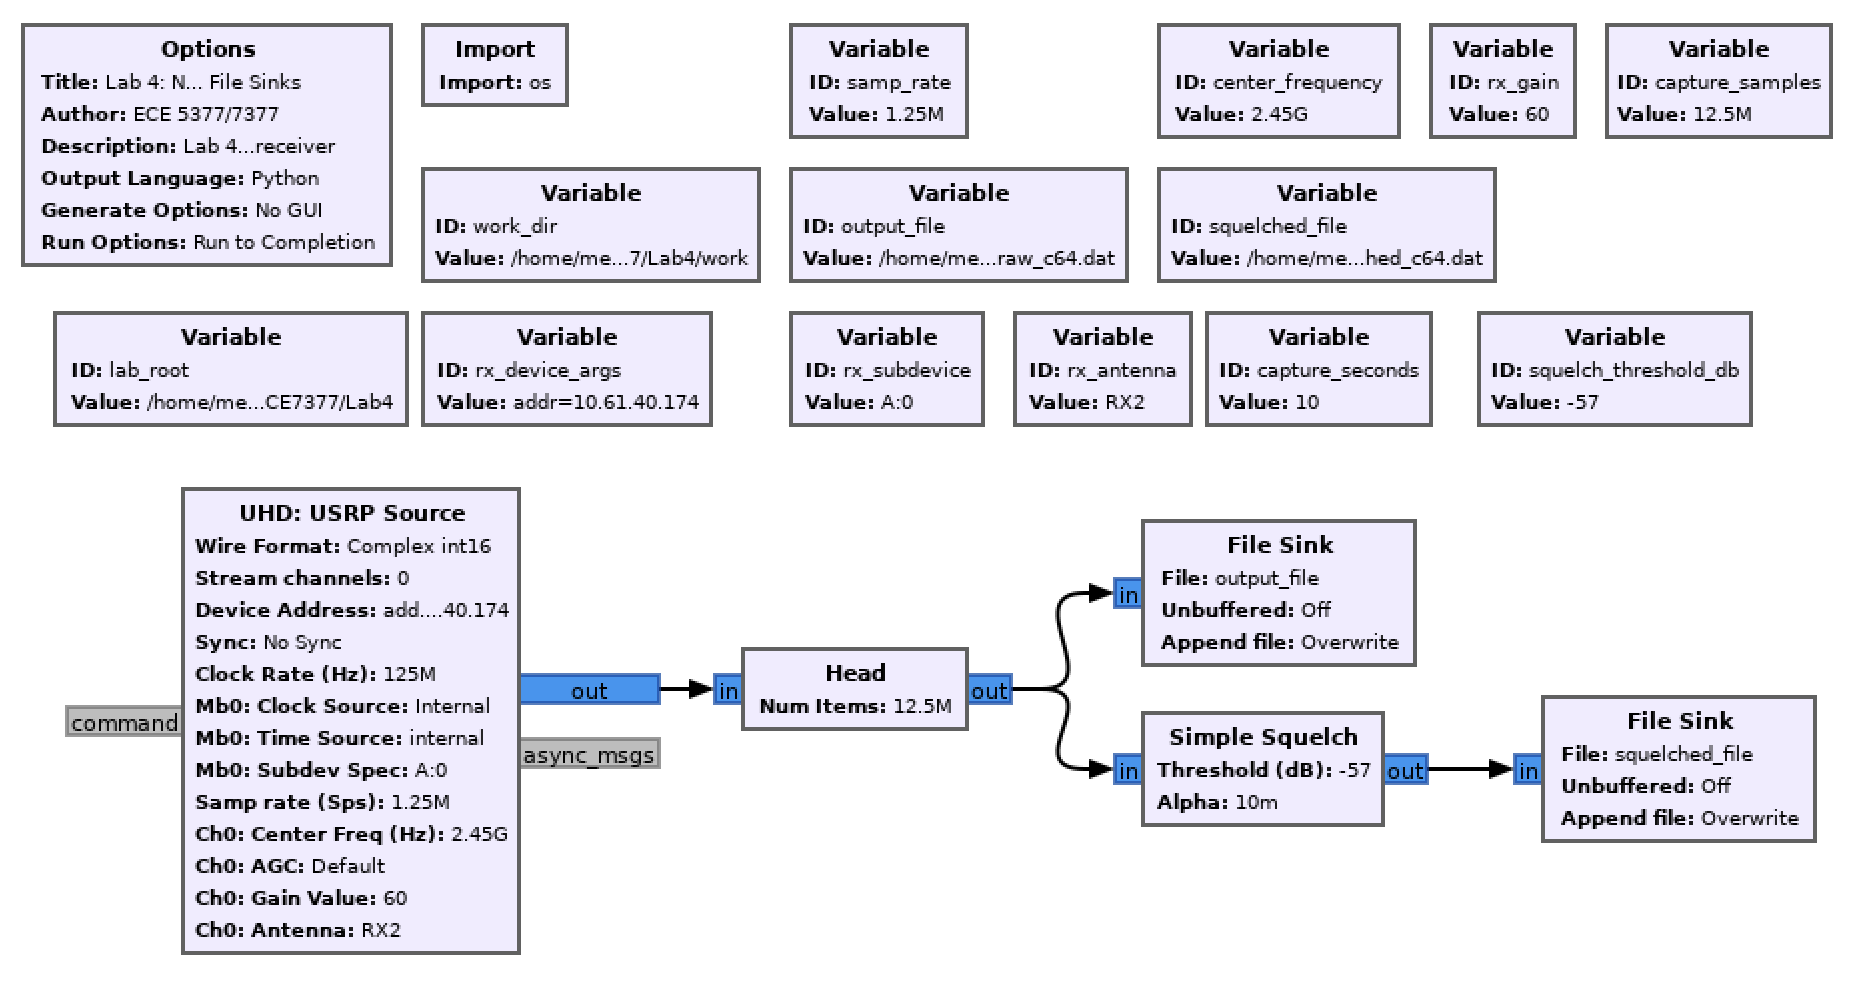

## Analyze the nominal real capture


<span style="color:#165696"><b>Report.</b> Report noise and active power, squelch threshold, correlation peak sample (start sample), correlation evidence, CFO estimate, complex channel estimate $\hat h$, magnitude |$\hat h$|, phase, RMS EVM, and chip error rate. </span>

Noise power (dB): -72.7383837465147
Active power (dB): -41.57082571550792
Reproducible Squelch Threshold (dB): -57.0

Correlation Peak Sample (start sample): 11020797
CFO estimate (Hz): 134.8701097106028
Complex Channel estimate: (0.005812607707387879-0.004945816536811875j)
magnitude and phase (degrees): 0.007632005606378102 -40.3937090496357
SNR, EVM, chip error rate: 31.16423759955298 0.4424354325100743 0.0


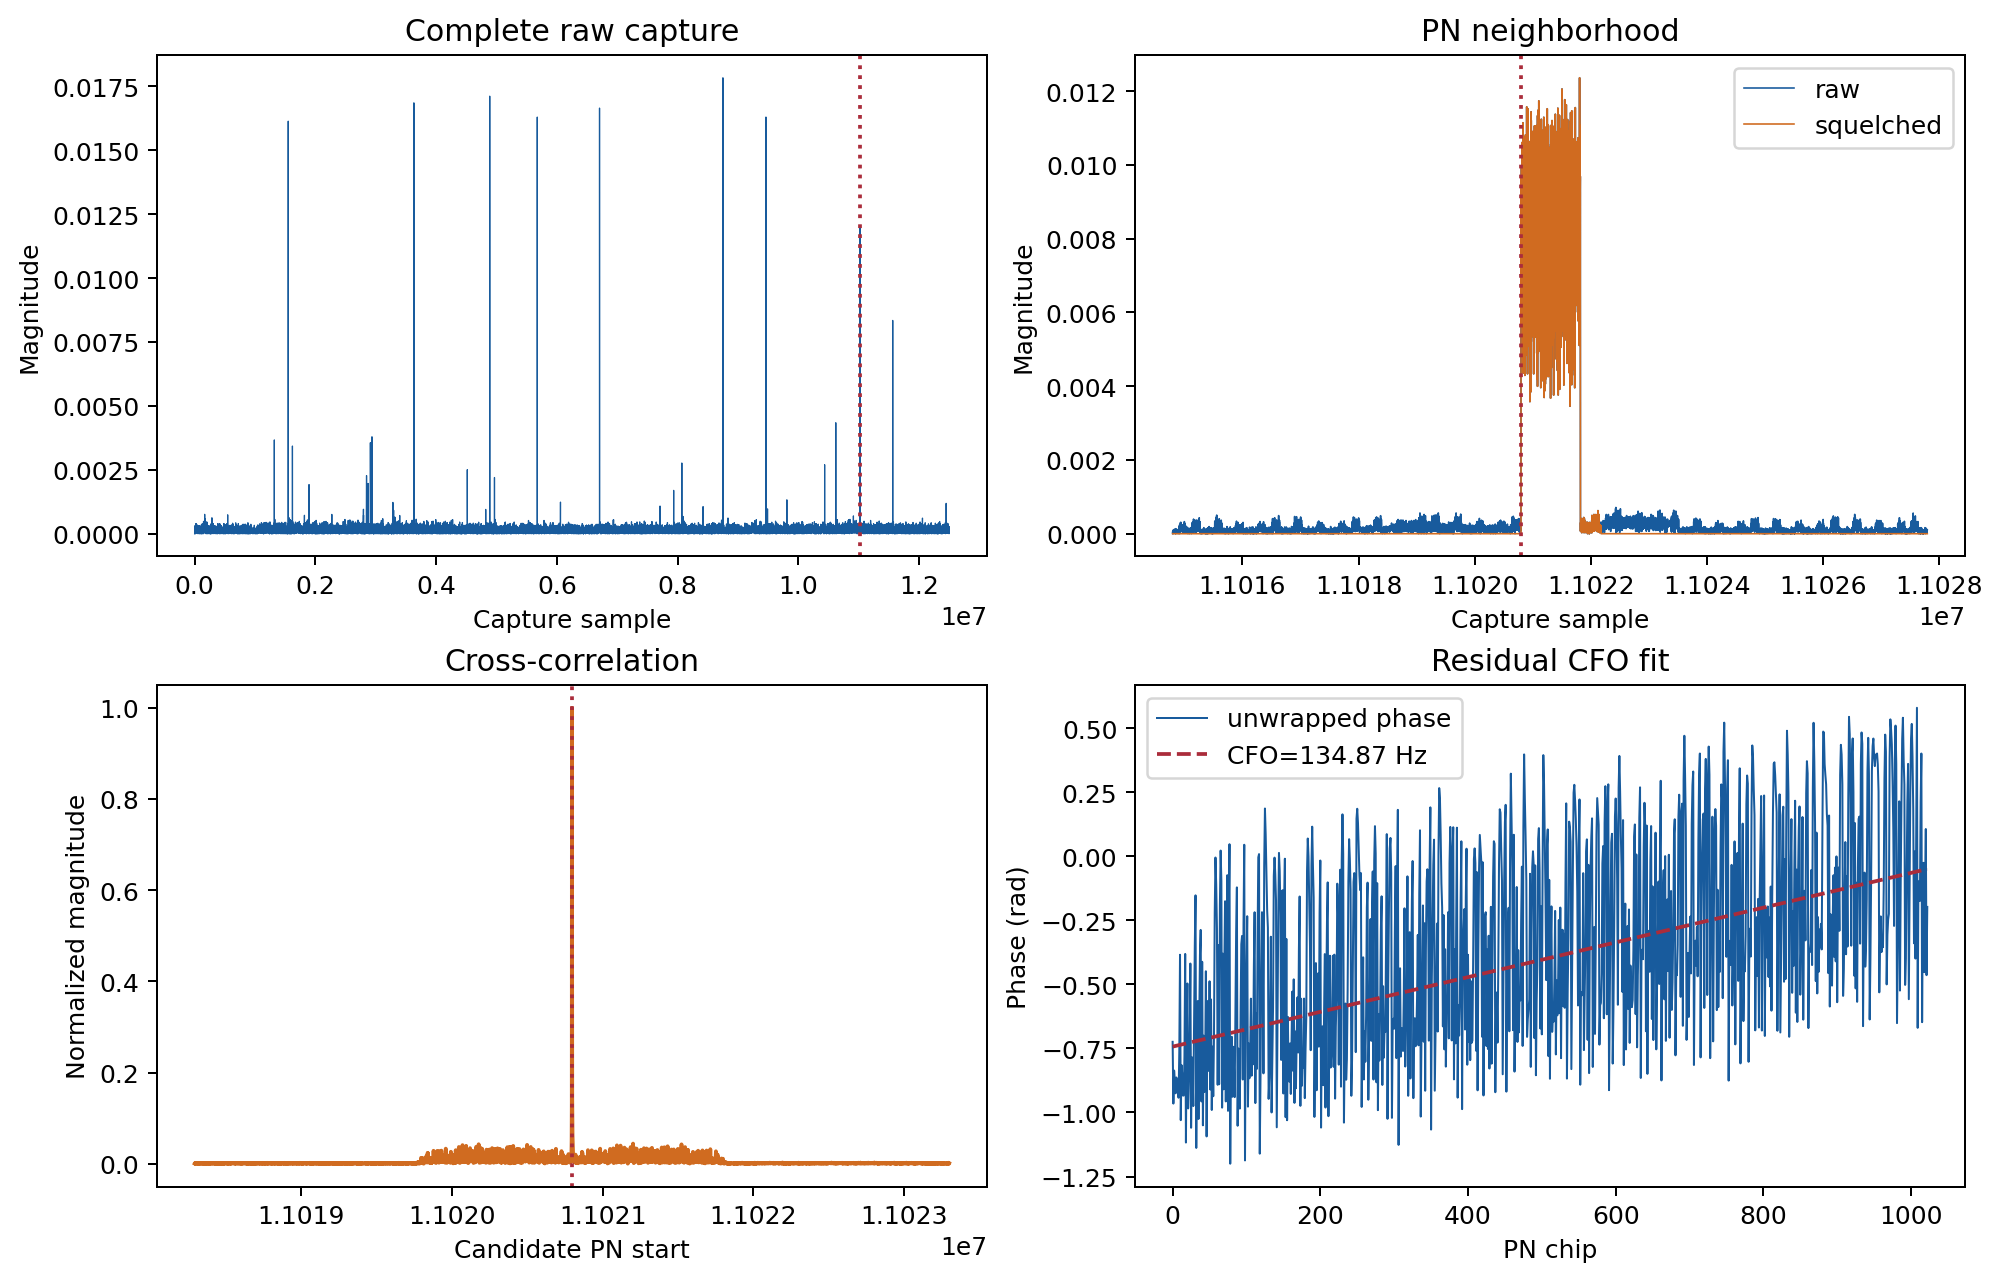

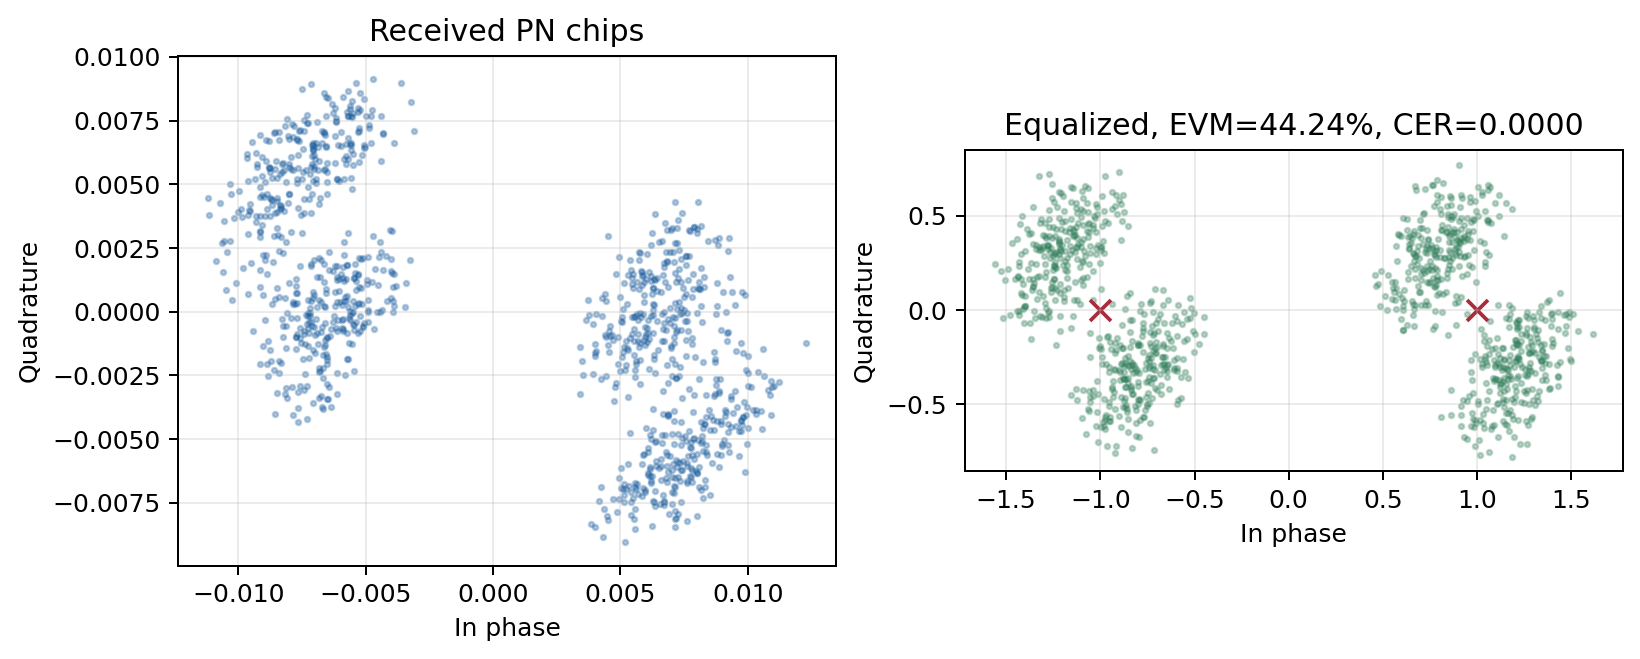

In [25]:
from lab4_dsp import pn_sequence
from lab4_tools import analyze_pn_capture, plot_real_pn_measurement

raw_path = CAPTURE_DIR / "task3_gain25_run1_raw_c64.dat"
squelched_path = CAPTURE_DIR / "task3_gain25_run1_squelched_c64.dat"
noise_path = CAPTURE_DIR / "task3_noise_c64.dat"
if not raw_path.is_file():
    raise FileNotFoundError(f"Run GNU Radio first. Missing {raw_path}")

record = analyze_pn_capture(
    raw_path,
    noise_path=noise_path,
    squelched_path=squelched_path,
)
training = pn_sequence(10)
corrected = np.asarray(record["corrected"])

# Calculate scalar least squares and equalize.
channel_estimate = np.vdot(training, corrected) / np.vdot(training, training)
equalized = corrected / channel_estimate

assert np.allclose(channel_estimate, record["channel"])
assert np.allclose(equalized, record["equalized"])
print("Noise power (dB):", record["noise_power_db"])
print("Active power (dB):", record["active_power_db"])
print(f"Reproducible Squelch Threshold (dB): {np.round((record['noise_power_db'] + record['active_power_db']) / 2)}")
print()
print("Correlation Peak Sample (start sample):", record["start_sample"])
print("CFO estimate (Hz):", record["cfo_hz"])
print("Complex Channel estimate:", channel_estimate)
print("magnitude and phase (degrees):", abs(channel_estimate), np.rad2deg(np.angle(channel_estimate)))
print("SNR, EVM, chip error rate:", record["snr_db"], record["evm"], record["chip_error_rate"])

for path in plot_real_pn_measurement(record, FIGURE_DIR):
    display(Image(filename=path))


<span style="color:#165696"><b>Report.</b> Explain why the raw capture is retained even when a squelched file is available. </span>

The raw capture preserves the complete received signal without applying squelch. Squelching can remove samples that fall below the selected threshold. Keeping the raw capture ensures that the original received data is still available.

<span style="color:#165696"><b>Report.</b> Explain why the raw branch is used for quantitative estimation. </span>

The raw branch is used because squelching modifies the received signal based on its power. This modification could affect measurements such as correlation, CFO, channel estimation, and EVM. Using the raw samples ensures these estimates are calculated from the unmodified received signal.

<span style="color:#165696"><b>Report.</b> Explain what physical and radio effects are included in the end-to-end scalar coefficient. </span>

The end-to-end scalar coefficient $\hat{h}$ represents the combined effect of the entire radio link on the transmitted signal. It includes the 0.08 transmit amplitude, transmitter and receiver gains, antenna effects, propagation through the channel, receiver scaling, and common phase shift. Therefore, $|\hat h|$ describes the overall amplitude scaling, while its phase describes the overall phase shift. It is not a calibrated measurement of path loss or voltage.